# Ejercicio 1: Alarma

**Red:** Robo (B) → Alarma (A) ← Terremoto (E); Alarma → JuanLlama (J); Alarma → MariaLlama (M)

| Probabilidad | Valor |
|---|---|
| P(B=1) | 0.01 |
| P(E=1) | 0.02 |
| P(A=1 \| B=0, E=0) | 0.001 |
| P(A=1 \| B=0, E=1) | 0.29 |
| P(A=1 \| B=1, E=0) | 0.94 |
| P(A=1 \| B=1, E=1) | 0.95 |
| P(J=1 \| A=1) / P(J=1 \| A=0) | 0.9 / 0.05 |
| P(M=1 \| A=1) / P(M=1 \| A=0) | 0.7 / 0.01 |

**a)** Define el modelo y las CPDs y compruébalo con `check_model()`.
**b)** Dibuja el grafo y guárdalo como `alarm.png`.
**c)** Calcula P(B | J=1, M=1) y P(B | J=1, M=1, E=1). Explica por qué baja la probabilidad de robo.
**d)** Comprueba con `is_dconnected` si B ⊥ E y si B ⊥ E | A. Justifícalo.

Model OK: True
+------+------+------+
| A    | A(0) | A(1) |
+------+------+------+
| M(0) | 0.99 | 0.3  |
+------+------+------+
| M(1) | 0.01 | 0.7  |
+------+------+------+


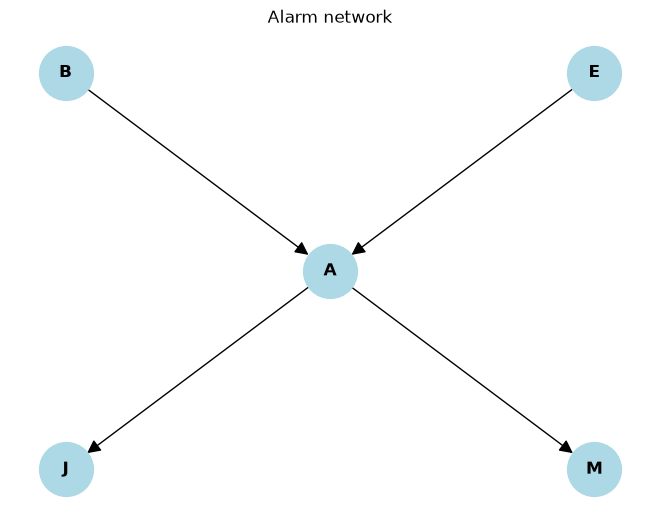

In [ ]:
import warnings
warnings.filterwarnings("ignore")                      # hide pgmpy deprecation warnings

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx                                  # to draw the graph
from itertools import product

from pgmpy.models import DiscreteBayesianNetwork       # (older pgmpy: BayesianNetwork)
from pgmpy.factors.discrete import TabularCPD          # conditional probability tables
from pgmpy.inference import VariableElimination        # exact inference


# 1 Definimsos el modelo Quien apunta a quien
alarm_model = DiscreteBayesianNetwork([("B","A"), ("E","A"), ("A", "J"), ("A","M")])

# 2 Creamos las CPD para cada variable
# 1 la variable, 2 -> posibles valores que puede tomar
# 3 -> Lista de probabilidades
# Con padres, metemos varios valores juntos segun las distintas opciones 
# ponemos los padres en evidence y los posibles valores de ellos
cpd_b = TabularCPD("B", 2, [[0.99],  # fila B = 0 no robo
                            [0.01]]) # fila B = 1 roban
cpd_e = TabularCPD("E", 2,[[0.98], [0.02]]) # igual para E (no tienen padres)
                        #B=0,E=0,  0,1  1,0  1,1 
cpd_a = TabularCPD("A", 2,  [[0.999,0.71,0.06,0.05],    #Fila A =0
                            [0.001,0.29,0.94,0.95]], evidence=["B","E"], evidence_card=[2,2]) #fila A = 1
                            # A = 0, A = 1
cpd_j = TabularCPD("J", 2, [[0.95,0.1], # J = 0
                           [0.05,0.9]],evidence=["A"], evidence_card=[2]) # J = 1 

cpd_m = TabularCPD("M", 2, [[0.99,0.3], # M = 0
                           [0.01,0.7]],evidence=["A"], evidence_card=[2]) # M = 1 
alarm_model.add_cpds(cpd_b, cpd_e, cpd_a, cpd_j,cpd_m)
print("Model OK:", alarm_model.check_model())
print(cpd_m)
#b)
pos = {"B": (-1, 2), "E": (1, 2), "A": (0, 1), "J": (-1, 0), "M": (1, 0)}

G = nx.DiGraph(alarm_model.edges())          # el grafo sale del modelo, así que siempre cuadra
nx.draw(G, pos, with_labels=True, node_size=1500, node_color="lightblue",
        arrowsize=20, font_weight="bold")
plt.title("Alarm network")
plt.savefig("alarm.png", dpi=150, bbox_inches="tight")
plt.show()



In [ ]:
#c Calcular las probabilidades

# Creamos el motor de inferencia
infer = VariableElimination(alarm_model)

#P(B | J=1, M=1): probabilidad de robo si llaman a juan y maria
q1 = infer.query(variables=["B"], evidence={"J": 1, "M": 1})
print(q1)
#VARIABLE = LO QUE QUEREMOS SABER, EVIDENCE LO QUE SABEMOS
#P(B | J=1, M=1, E=1): probabilidad de robo si llaman a juan y maria
q2 = infer.query(variables=["B"], evidence={"J": 1, "M": 1, "E":1})
print(q2)


#Baja porque las llamadas indican que la alarma ha sonado, y si sabes que hubo un terremoto
# el terremoto ya explica la alarma, asique el robo se vuelve menos necesario


+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.4435 |
+------+----------+
| B(1) |   0.5565 |
+------+----------+
+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.9680 |
+------+----------+
| B(1) |   0.0320 |
+------+----------+


In [ ]:
#d
#Aplica a cada nodo a regla sabiendo sus padres, un nodo es independiente
#de todo lo que no sea su padre o descendiente.
print(alarm_model.local_independencies(["B", "E", "A", "M", "J"]))
print("B ⊥ E  ?", not alarm_model.is_dconnected("B", "E"))
print("B ⊥ E | A    ?", not alarm_model.is_dconnected("B", "E", observed=["A"]))

(B ⟂ E)
(E ⟂ B)
(J ⟂ B, E, M | A)
(M ⟂ B, E, J | A)
B ⊥ E  ? True
B ⊥ E | A    ? False


2. El unico camino es B -> A <- E, es un colisionador y no esta observado asique la valvula esta cerrada. Son independientes, que haya un robo no tiene nada que ver con que haya un terremoto

3. Es el mismo camino, al estar A observado abre la valvula asique son dependientes. Si sabes que sono la alarma y  te dice que hubo terremoto, el robo se vuelve menos probable

**B ⊥ E → True.** The only path between them is B → A ← E. A is a collider and it is not observed, so the path is blocked. Therefore B and E are independent: a burglary has nothing to do with an earthquake.

**B ⊥ E | A → False.** It is the same path, but now A is observed, and an observed collider opens the path. Therefore B and E are dependent given A: if we know the alarm went off and we are told there was an earthquake, a burglary becomes less likely, because the earthquake already explains the alarm (explaining away).

Aquí la tienes en español:

**Pregunta tipo:** ¿X ⊥ Y | Z? (Z son las variables que conoces u observas)

**Los 3 tipos de nodo en un camino**

| Tipo | Forma | C NO observado | C observado |
|---|---|---|---|
| Cadena | X → C → Y | ✅ abierto | ❌ cerrado |
| Causa común | X ← C → Y | ✅ abierto | ❌ cerrado |
| Colisionador | X → C ← Y | ❌ cerrado | ✅ abierto |

**Regla extra del colisionador:** también se **abre** si observas un **hijo o descendiente** de C. Por ejemplo, en B → A ← E con A → J, si sabes que Juan llamó (J), el camino entre B y E se abre.

**Truco:** en la cadena y la causa común, observar **cierra** el camino. En el colisionador es al revés: observar **abre**.

**Receta paso a paso**
1. Busca **todos los caminos** entre X e Y, sin mirar hacia dónde van las flechas.
2. En cada camino, mira cada nodo del medio: ¿de qué tipo es? ¿está observado?
3. Un camino está **abierto** solo si **todos** sus nodos del medio están abiertos.
4. Si **algún** camino está abierto, son **dependientes**. Si **todos** están cerrados, son **independientes**.

**Regla de Markov local:** cada nodo es independiente de todo lo que no sea su descendiente, si conoces sus padres.

**Comprobar con pgmpy**
- `model.is_dconnected("X", "Y", observed=["Z"])` devuelve `True` si son dependientes y `False` si son independientes.
- `model.local_independencies([...])` aplica la regla de Markov local.

**Ejemplos clásicos**
- Lluvia → Césped ← Aspersor: sin saber nada, independientes. Sabiendo Césped, dependientes (*explaining away*).
- Offer ← Spam → Enlaces: sin saber nada, dependientes. Sabiendo Spam, independientes.
- Nublado → Lluvia → Césped: sin saber nada, dependientes. Sabiendo Lluvia, independientes.

CHULETA
# D-separation cheat sheet

**Question:** Is X ⊥ Y | Z ? (Z = observed variables)

## The 3 types of node on a path

| Type | Shape | Z does NOT contain C | Z contains C |
|---|---|---|---|
| Chain | X → C → Y | ✅ open | ❌ blocked |
| Common cause (fork) | X ← C → Y | ✅ open | ❌ blocked |
| Collider (v-structure) | X → C ← Y | ❌ blocked | ✅ open |

**Collider extra rule:** a collider is also OPEN if any **descendant** of C is observed.
Example: B → A ← E, A → J. Observing J opens B – E.

**Memory trick:** chain and fork → observing **closes**. Collider → observing **opens** (the opposite).

## Recipe
1. List **all paths** between X and Y (ignore arrow direction).
2. For each middle node, check its type and whether it is observed.
3. A path is **open** only if **every** middle node is open.
4. **Any open path → dependent.** All paths blocked → independent (d-separated).

## Local Markov property
Each node ⊥ its non-descendants | its parents.

## Check with pgmpy
model.is_dconnected("X", "Y", observed=["Z"])   # True = dependent, False = independent
model.local_independencies(["X", "Y"])
model.get_independencies()                      # all independencies

## Classic examples
- Rain → WetGrass ← Sprinkler: Rain ⊥ Sprinkler ✅ ; Rain ⊥ Sprinkler | WetGrass ❌ (explaining away)
- Offer ← Spam → Links: Offer ⊥ Links ❌ ; Offer ⊥ Links | Spam ✅
- Cloudy → Rain → WetGrass: Cloudy ⊥ WetGrass ❌ ; Cloudy ⊥ WetGrass | Rain ✅

# Ejercicio 2: Diagnóstico de gripe

**Red:** Gripe (G) → Fiebre (F); Gripe → Tos (T); Gripe → Cansancio (C); Fiebre → Cansancio

| Probabilidad | Valor |
|---|---|
| P(G=1) | 0.15 |
| P(F=1 \| G=1) / P(F=1 \| G=0) | 0.8 / 0.1 |
| P(T=1 \| G=1) / P(T=1 \| G=0) | 0.7 / 0.2 |
| P(C=1 \| G=0, F=0) | 0.1 |
| P(C=1 \| G=0, F=1) | 0.5 |
| P(C=1 \| G=1, F=0) | 0.4 |
| P(C=1 \| G=1, F=1) | 0.9 |

**a)** Define el modelo y guarda el grafo como `flu.png`.
**b)** Muestra `local_independencies` y explica una de ellas.
**c)** Recorre las 8 combinaciones de (F, T, C) con `itertools.product`, imprime P(G=1 | F, T, C) y marca "GRIPE" si pasa de 0.5.
**d)** ¿Qué síntoma pesa más? Razónalo.

In [6]:
# 1 Definimsos el modelo Quien apunta a quien
flu_model = DiscreteBayesianNetwork([("G","C"), ("G","F"), ("G", "T"), ("F","C")])

# 2 Creamos las CPD para cada variable
# 1 la variable, 2 -> posibles valores que puede tomar
# 3 -> Lista de probabilidades
# Con padres, metemos varios valores juntos segun las distintas opciones 
# ponemos los padres en evidence y los posibles valores de ellos
cpd_g = TabularCPD("G", 2, [[0.85],  # fila B = 0 no robo
                            [0.15]]) # fila B = 1 roban
cpd_f = TabularCPD("F", 2,  [[0.9,0.2],    #Fila A =0
                            [0.1,0.8]], evidence=["G"], evidence_card=[2]) #fila A = 1
cpd_t = TabularCPD("T", 2,  [[0.8,0.3],    #Fila A =0
                            [0.2,0.7]], evidence=["G"], evidence_card=[2]) #fila A = 1
cpd_c = TabularCPD("C", 2,  [[0.9,0.5,0.6,0.1],    #Fila A =0
                            [0.1,0.5,0.4,0.9]], evidence=["G","F"], evidence_card=[2,2]) #fila A = 1
flu_model.add_cpds(cpd_g, cpd_f, cpd_t, cpd_c)
print("Model OK:", flu_model.check_model())
print(cpd_c)

Model OK: True
+------+------+------+------+------+
| G    | G(0) | G(0) | G(1) | G(1) |
+------+------+------+------+------+
| F    | F(0) | F(1) | F(0) | F(1) |
+------+------+------+------+------+
| C(0) | 0.9  | 0.5  | 0.6  | 0.1  |
+------+------+------+------+------+
| C(1) | 0.1  | 0.5  | 0.4  | 0.9  |
+------+------+------+------+------+


In [ ]:
#b
print(flu_model.local_independencies(["G", "C", "F", "T"]))


(C ⟂ T | F, G)
(F ⟂ T | G)
(T ⟂ C, F | G)


**C ⊥ T | F, G.** The parents of Tiredness (C) are Flu (G) and Fever (F). Tiredness and Cough are only connected through Flu (T ← G → C, a common cause). Once we know G (and F), that path is blocked, so knowing whether the patient coughs gives no extra information about tiredness.

**F ⊥ T | G.** Fever and Cough are connected through Flu (F ← G → T, common cause), which is blocked because G is observed. The other path, F → C ← G → T, is blocked at the collider C, which is not observed. All paths are blocked, so knowing the fever gives no extra information about the cough.


**T ⊥ C,F | G.** Ffiebre y tos estan conectdos por gripe, common cause, esta bloqueado por observacion. tos y cansancion estan tambien conectador por gripe, pasa lo mismo. por el otro camino estan bloqueados por F (chain) que al no estar observador esta bloqueado. Po lo que sabiendo Tos no nos da mas informacions sobre cansacion o fiebre

✅ El motivo real: todos los caminos que salen de T pasan por G, porque T solo tiene a G como vecino. El otro camino es T ← G → F → C, y en G (causa común, observada) ya se corta. Da igual cómo esté F.

In [ ]:
#Apartado C
infer = VariableElimination(flu_model)

print(" F, T, C | P(G=1|F,T,C) | class")
for f, t, c in product([0, 1], repeat=3):                 # all 8 possible e-mails
    posterior = infer.query(["G"], evidence={"F": f, "T": t, "C": c}, show_progress=False)
    p_flu = posterior.values[1] 
    #p_flu = posterior.values[1]
    #posterior tiene dos números: values[0] = P(G=0) (sin gripe) y values[1] = P(G=1) (con gripe). Te quedas con el de gripe                          # values[1] = P(S = 1 | evidence)
    print(f" {f} {t} {c} |    {p_flu:.4f}     | {'GRIPE' if p_flu > 0.5 else 'not spam'}")

 F, T, C | P(G=1|F,T,C) | class
 0 0 0 |    0.0097     | not spam
 0 0 1 |    0.0556     | not spam
 0 1 0 |    0.0838     | not spam
 0 1 1 |    0.3544     | not spam
 1 0 0 |    0.0957     | not spam
 1 0 1 |    0.4880     | not spam
 1 1 0 |    0.4970     | not spam
 1 1 1 |    0.8989     | GRIPE
